# CIFAR-10 Model Comparison

This notebook compares MLP and CNN models on the CIFAR-10 dataset, trains them, evaluates accuracy and loss, and summarizes which architecture performs better.

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

print(torch.__version__)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DEVICE

2.13.0+cpu


device(type='cpu')

Train size: 50000
Test size: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894737..2.0942786].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9100897..2.100835].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.6581874..2.1264887].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.7709224..1.7256967].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894737..2.0432324].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8997625..2.011479].


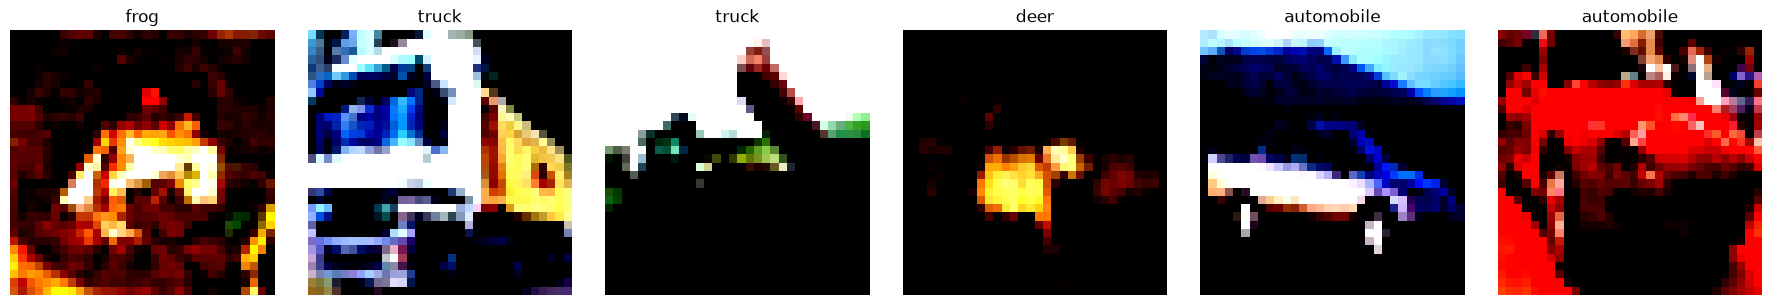

In [5]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
])

train_dataset = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

class_names = train_dataset.classes
print('Train size:', len(train_dataset))
print('Test size:', len(test_dataset))
print('Classes:', class_names)

fig, axes = plt.subplots(1, 6, figsize=(18, 3))
for ax, idx in zip(axes, range(6)):
    image, label = train_dataset[idx]
    ax.imshow(image.permute(1,2,0).numpy())
    ax.set_title(class_names[label])
    ax.axis('off')
plt.tight_layout()
plt.show()

In [6]:
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False, num_workers=2)

In [7]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(32*32*3, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 10)
    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

mlp_model = MLP().to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(mlp_model.parameters(), lr=1e-3)

train_losses = []
train_accs = []
for epoch in range(5):
    mlp_model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for images, labels in train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = mlp_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    train_losses.append(epoch_loss)
    train_accs.append(epoch_acc)
    print(f'Epoch {epoch+1}: loss={epoch_loss:.4f}, acc={epoch_acc:.4f}')

Epoch 1: loss=1.6417, acc=0.4203
Epoch 2: loss=1.4363, acc=0.4919
Epoch 3: loss=1.3354, acc=0.5295
Epoch 4: loss=1.2535, acc=0.5574
Epoch 5: loss=1.1888, acc=0.5784


In [8]:
def evaluate_model(model, loader):
    model.eval()
    correct = 0
    total = 0
    losses = []
    preds = []
    targets = []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            loss = criterion(outputs, labels)
            losses.append(loss.item())
            preds.extend(outputs.argmax(1).cpu().tolist())
            targets.extend(labels.cpu().tolist())
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    acc = correct / total
    return acc, np.mean(losses), np.array(preds), np.array(targets)

mlp_acc, mlp_loss, mlp_preds, mlp_targets = evaluate_model(mlp_model, test_loader)
print('MLP test accuracy:', mlp_acc)
print('MLP test loss:', mlp_loss)

MLP test accuracy: 0.515
MLP test loss: 1.3745574739914905


In [10]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(128*8*8, 256)
        self.fc2 = nn.Linear(256, 10)
    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

cnn_model = CNN().to(DEVICE)
optimizer = torch.optim.Adam(cnn_model.parameters(), lr=1e-3)

cnn_train_losses = []
cnn_train_accs = []
for epoch in range(5):
    cnn_model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for images, labels in train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = cnn_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    cnn_train_losses.append(epoch_loss)
    cnn_train_accs.append(epoch_acc)
    print(f'CNN Epoch {epoch+1}: loss={epoch_loss:.4f}, acc={epoch_acc:.4f}')

cnn_acc, cnn_loss, cnn_preds, cnn_targets = evaluate_model(cnn_model, test_loader)
print('CNN test accuracy:', cnn_acc)
print('CNN test loss:', cnn_loss)

CNN Epoch 1: loss=1.2910, acc=0.5387
CNN Epoch 2: loss=0.8276, acc=0.7099
CNN Epoch 3: loss=0.6305, acc=0.7805
CNN Epoch 4: loss=0.4628, acc=0.8380
CNN Epoch 5: loss=0.3128, acc=0.8905
CNN test accuracy: 0.7619
CNN test loss: 0.7729353169097176


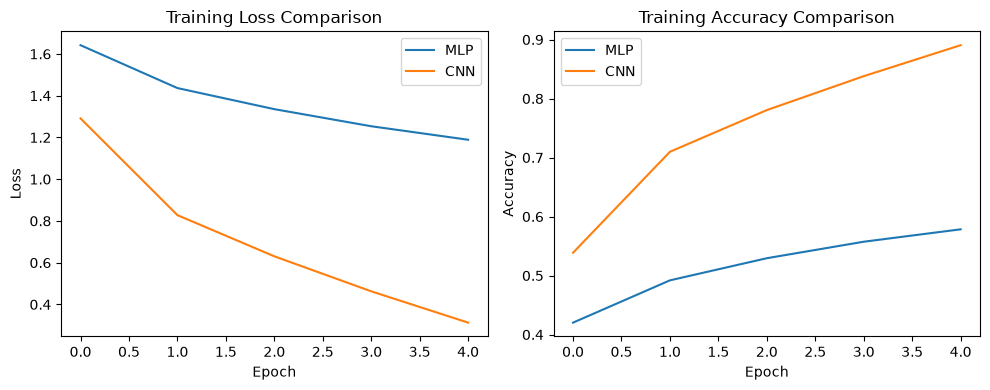

MLP accuracy: 0.515
CNN accuracy: 0.7619
Best model: CNN


In [11]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='MLP')
plt.plot(cnn_train_losses, label='CNN')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Training Loss Comparison')

plt.subplot(1, 2, 2)
plt.plot(train_accs, label='MLP')
plt.plot(cnn_train_accs, label='CNN')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training Accuracy Comparison')
plt.tight_layout()
plt.show()

print('MLP accuracy:', mlp_acc)
print('CNN accuracy:', cnn_acc)
print('Best model:', 'CNN' if cnn_acc > mlp_acc else 'MLP')